In [1]:
import torch
torch.cuda.empty_cache()
from PIL import Image
import requests
from transformers import SamModel, SamProcessor

model = SamModel.from_pretrained("facebook/sam-vit-base").cuda()
processor = SamProcessor.from_pretrained("facebook/sam-vit-base")

img_url = "https://huggingface.co/ybelkada/segment-anything/resolve/main/assets/car.png"
raw_image = Image.open(requests.get(img_url, stream=True).raw).convert("RGB")
input_points = [[[450, 600]]] # 2D localization of a window


c:\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import torch
inputs = processor(raw_image, input_points=input_points, return_tensors="pt").to("cuda")
inputs = inputs.to(torch.float32)
outputs = model(**inputs)
masks = processor.image_processor.post_process_masks(outputs.pred_masks.cpu(), inputs["original_sizes"].cpu(), inputs["reshaped_input_sizes"].cpu())
scores = outputs.iou_scores

torch.Size([1, 1, 3])


In [2]:
!pip install tf-keras
from transformers import pipeline
generator =  pipeline("mask-generation", device = 0, points_per_batch = 256)
image_url = "https://huggingface.co/ybelkada/segment-anything/resolve/main/assets/car.png"
outputs = generator(image_url, points_per_batch = 256)


No model was supplied, defaulted to facebook/sam-vit-huge and revision 997b15 (https://huggingface.co/facebook/sam-vit-huge).
Using a pipeline without specifying a model name and revision in production is not recommended.


OutOfMemoryError: CUDA out of memory. Tried to allocate 13.36 GiB. GPU 

In [5]:
# Load model directly
from transformers import AutoProcessor, AutoModelForMaskGeneration

processor = AutoProcessor.from_pretrained("facebook/sam-vit-base")
model = AutoModelForMaskGeneration.from_pretrained("facebook/sam-vit-base")
image_url = "https://huggingface.co/ybelkada/segment-anything/resolve/main/assets/car.png"
outputs = model(image_url, points_per_batch = 256)

AttributeError: 'str' object has no attribute 'shape'

: 

KeyError: 'masks'

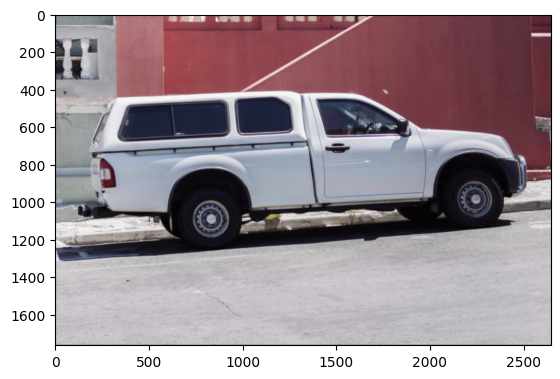

In [3]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30 / 255, 144 / 255, 255 / 255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)
    

plt.imshow(np.array(raw_image))
ax = plt.gca()
for mask in outputs["masks"]:
    show_mask(mask, ax=ax, random_color=True)
plt.axis("off")
plt.show()
